# 01 · Entendimento do negócio e dos dados

**Projeto:** novo modelo de prevenção a fraudes em pagamentos — FREEDOM
**Etapa:** 1 de 9

| # | Notebook | Pergunta que responde |
|---|---|---|
| **01** | **Entendimento do negócio e dos dados** | **O que temos em mãos e como vamos avaliar?** |
| 02 | Diagnóstico do score atual | Quão bom é o modelo em produção e onde ele falha? |
| 03 | Análise exploratória | Quais sinais separam fraude de transação legítima? |
| 04 | Engenharia de features | Como transformar esses sinais em variáveis seguras para produção? |
| 05 | Seleção de algoritmos | Qual família de modelos funciona melhor neste problema? |
| 06 | Modelo final | Tuning, calibração, explicabilidade e artefato final |
| 07 | Avaliação fora do tempo | O novo modelo supera o atual em dados nunca vistos? |
| 08 | Decisão de negócio | Qual ponto de corte maximiza o lucro? E se a fraude custar 10x? |
| 09 | Latência e produção | O modelo responde online, rápido e igual ao laboratório? |

### Metodologia
Usamos o **CRISP-DM** adaptado para fraude: entendimento do negócio → entendimento dos dados →
preparação → modelagem → avaliação → implantação. Duas adaptações importantes:

1. **Validação sempre fora do tempo (out-of-time).** Fraude é um problema adversarial e não
   estacionário: o modelo é treinado com o passado e decide sobre o futuro. Separações aleatórias
   superestimam o desempenho.
2. **Métrica final em R$.** A decisão é aprovar ou rejeitar um pagamento; o que importa no fim é o
   resultado financeiro, e não só a acurácia estatística.

## 1. Entendimento do negócio

**Decisão suportada pelo modelo:** para cada pagamento, *aprovar* ou *rejeitar* em tempo real.

| Resultado | O que acontece | Impacto |
|---|---|---|
| Legítima aprovada (VN) | Venda concluída | **+ receita** (comissão sobre o valor) |
| Fraude rejeitada (VP) | Perda evitada | 0 |
| Legítima rejeitada (FP) | Cliente bom bloqueado | **− receita perdida** + atrito com o cliente |
| Fraude aprovada (FN) | Chargeback | **− valor integral** do pagamento |

O custo é **assimétrico**: deixar passar uma fraude custa muito mais do que bloquear um bom pagamento.
Por isso a avaliação não pode usar acurácia. Com 5% de fraude, um modelo que aprova tudo já tem 95%
de acurácia e não serve para nada.

**Métricas que vamos acompanhar ao longo do projeto:**
- **PR AUC (Average Precision):** métrica principal de ordenação, sensível à classe rara.
- **ROC AUC e KS:** métricas clássicas de discriminação, comparáveis com o mercado.
- **Recall @ FPR x%:** quanto de fraude capturamos se aceitarmos bloquear x% dos bons clientes, que é
  a forma como o negócio enxerga o trade-off.
- **Lucro (R$):** métrica de decisão final, usada para escolher o ponto de corte.

In [1]:
# Configuração comum a todos os notebooks do projeto
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fraude import config as cfg, dados, metricas, graficos as gr

gr.aplicar_estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 40)

## 2. Carga e visão geral dos dados

In [2]:
df = dados.carregar_bruto()
print(f"{df.shape[0]:,} transações x {df.shape[1]} colunas")
df.head()

150,000 transações x 20 colunas


,a,b,c,d,e,f,g,h,i,j,k,l,m,n,o,p,fecha,monto,score,fraude
0,4,0.7685,"94,436.2400",20.0000,0.4448,1.0000,BR,5,Máquininha Corta Barba Cabelo Peito Perna Pelo...,cat_8d714cd,0.8836,240.0000,102.0000,1,<NA>,N,2020-03-27 11:51:16,5.6400,66,0
1,4,0.7550,"9,258.5000",1.0000,0.0000,33.0000,BR,0,Avental Descartavel Manga Longa - 50 Un. Tnt ...,cat_64b574b,0.3760,"4,008.0000",0.0000,1,Y,N,2020-04-15 19:58:08,124.7100,72,0
2,4,0.7455,"242,549.0900",3.0000,0.0000,19.0000,AR,23,Bicicleta Mountain Fire Bird Rodado 29 Alumini...,cat_e9110c5,0.5164,"1,779.0000",77.0000,1,<NA>,N,2020-03-25 18:13:38,339.3200,95,0
3,4,0.7631,"18,923.9000",50.0000,0.4824,18.0000,BR,23,Caneta Delineador Carimbo Olho Gatinho Longo 2...,cat_d06e653,0.1540,"1,704.0000","1,147.0000",1,<NA>,Y,2020-04-16 16:03:10,3.5400,2,0
4,2,0.7315,"5,728.6800",15.0000,0.0000,1.0000,BR,2,Resident Evil Operation Raccoon City Ps3,cat_6c4cfdc,0.8558,"1,025.0000",150.0000,1,<NA>,N,2020-04-02 10:24:45,3.5300,76,0


As variáveis `a`…`p` estão **anonimizadas**: não sabemos o significado de negócio de cada uma.
Por isso a análise vai inferir o papel de cada variável pelo comportamento. Abaixo, o perfil de cada coluna.

In [3]:
perfil = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos_%": df.isna().mean() * 100,
    "valores_unicos": df.nunique(),
    "min": df.select_dtypes("number").min(),
    "mediana": df.select_dtypes("number").median(),
    "max": df.select_dtypes("number").max(),
})
perfil

,tipo,nulos_%,valores_unicos,min,mediana,max
a,int64,0.0000,4,1.0000,4.0000,4.0000
b,float64,8.6560,7672,0.0000,0.7555,1.0000
c,float64,8.6560,135090,0.1600,"43,711.6550","13,878,743.7100"
d,float64,0.2433,51,0.0000,14.0000,50.0000
e,float64,0.0000,43208,0.0000,0.1049,833.3333
f,float64,0.0073,1338,-5.0000,8.0000,"145,274.0000"
fecha,datetime64[us],0.0000,145813,NaN,NaN,NaN
fraude,int64,0.0000,2,0.0000,0.0000,1.0000
g,string,0.1293,51,NaN,NaN,NaN
h,int64,0.0000,59,0.0000,9.0000,58.0000


**Leitura inicial do dicionário (inferido):**

| Coluna | Tipo inferido | Observação |
|---|---|---|
| `a` | ordinal (1–4) | 4 níveis, maioria = 4 |
| `b` | contínua [0,1] | parece um índice/score; 8,7% nulos |
| `c` | contínua, muito assimétrica | escala de "volume" (até 13,9 mi); nula junto com `b` |
| `d` | discreta (0–50) | concentrada em 50 (teto?) |
| `e` | razão ≥ 0 | maioria entre 0 e 1, com caudas extremas |
| `f` | contagem (−5 a 145 mil) | **valores negativos** (−5) que não fazem sentido para contagem |
| `g` | país (51 códigos ISO) | BR e AR dominam |
| `h` | contagem (0–58) | |
| `i` | **texto: título do produto** | 127,8 mil títulos distintos |
| `j` | **categoria do produto** (hash) | 8,3 mil categorias |
| `k` | contínua [0,1] | **um valor distinto por linha**: suspeita de ruído/ID |
| `l`, `m` | contagens/tempos | `l` até 7,5 mil, `m` até 2,2 mil |
| `n` | binária | |
| `o` | Y / N / **nulo** (72,6% nulos) | |
| `p` | Y / N | |
| `fecha` | data-hora da transação | 08/03/2020 a 21/04/2020 |
| `monto` | valor do pagamento | de 0,02 a 3,7 mil |
| `score` | score do modelo atual (0–100) | baseline |
| `fraude` | **alvo** (1 = fraude) | |

## 3. Qualidade dos dados

In [4]:
print("Linhas duplicadas:", df.duplicated().sum())
print("Valores únicos de k == nº de linhas:", df["k"].nunique() == len(df))
print("Registros com f negativo:", (df["f"] < 0).sum())

# Os nulos acontecem em blocos? (mesma origem -> mesma informação faltante)
print("\nb e c nulos simultaneamente:", (df["b"].isna() == df["c"].isna()).mean() * 100, "%")
print("d e m nulos simultaneamente:", (df["d"].isna() == df["m"].isna()).mean() * 100, "%")

Linhas duplicadas: 0
Valores únicos de k == nº de linhas: True
Registros com f negativo: 1277

b e c nulos simultaneamente: 100.0 %
d e m nulos simultaneamente: 100.0 %


Os nulos aparecem em **blocos**: `b` e `c` faltam sempre juntos, assim como `d` e `m`. Isso indica
que cada par vem de uma mesma fonte de dados (um mesmo serviço/tabela de origem). A pergunta seguinte
é se a ausência carrega informação de risco.

In [5]:
nulos = pd.DataFrame({
    "b/c nulos": df.groupby(df["b"].isna())["fraude"].mean(),
    "d/m nulos": df.groupby(df["d"].isna())["fraude"].mean(),
    "o nulo": df.groupby(df["o"].isna())["fraude"].mean(),
}).T
nulos.columns = ["preenchido", "nulo"]
nulos.style.format("{:.2%}")

,preenchido,nulo
b/c nulos,4.87%,6.38%
d/m nulos,4.99%,7.95%
o nulo,12.79%,2.05%


**A ausência é informativa, mas em direções diferentes.** Faltar `b/c` ou `d/m` **aumenta** a taxa de
fraude (de 5% para 6,4–7,9%). Já faltar `o` **reduz** (2% contra 6,5–22% quando preenchido).
**Decisão:** não imputar cegamente. Modelos de árvore usarão o nulo como informação nativa, e modelos
lineares receberão indicadores de ausência.

## 4. Variável alvo e comportamento no tempo

In [6]:
print(f"Taxa de fraude: {df['fraude'].mean():.2%}  ({df['fraude'].sum():,} fraudes)")
print(f"Período: {df['fecha'].min()}  ->  {df['fecha'].max()}  ({df['fecha'].dt.normalize().nunique()} dias)")

diario = (df.set_index("fecha").resample("D")["fraude"]
            .agg(transacoes="size", fraudes="sum", taxa="mean"))

# Resumo por "regime" (os recortes vêm da inspeção do gráfico abaixo)
regime = pd.cut(diario.index, [pd.Timestamp("2020-03-07"), pd.Timestamp("2020-03-25"),
                               pd.Timestamp("2020-04-02"), pd.Timestamp("2020-04-21")],
                labels=["08/03-25/03", "26/03-02/04", "03/04-21/04"])
diario.groupby(regime, observed=True).agg(dias=("taxa", "size"), transacoes_por_dia=("transacoes", "mean"),
                                          taxa_fraude=("taxa", "mean"))

Taxa de fraude: 5.00%  (7,500 fraudes)
Período: 2020-03-08 00:02:15  ->  2020-04-21 23:59:56  (45 dias)


,dias,transacoes_por_dia,taxa_fraude
08/03-25/03,18,"3,545.8889",0.0474
26/03-02/04,8,"2,307.2500",0.0636
03/04-21/04,19,"3,564.0000",0.0493


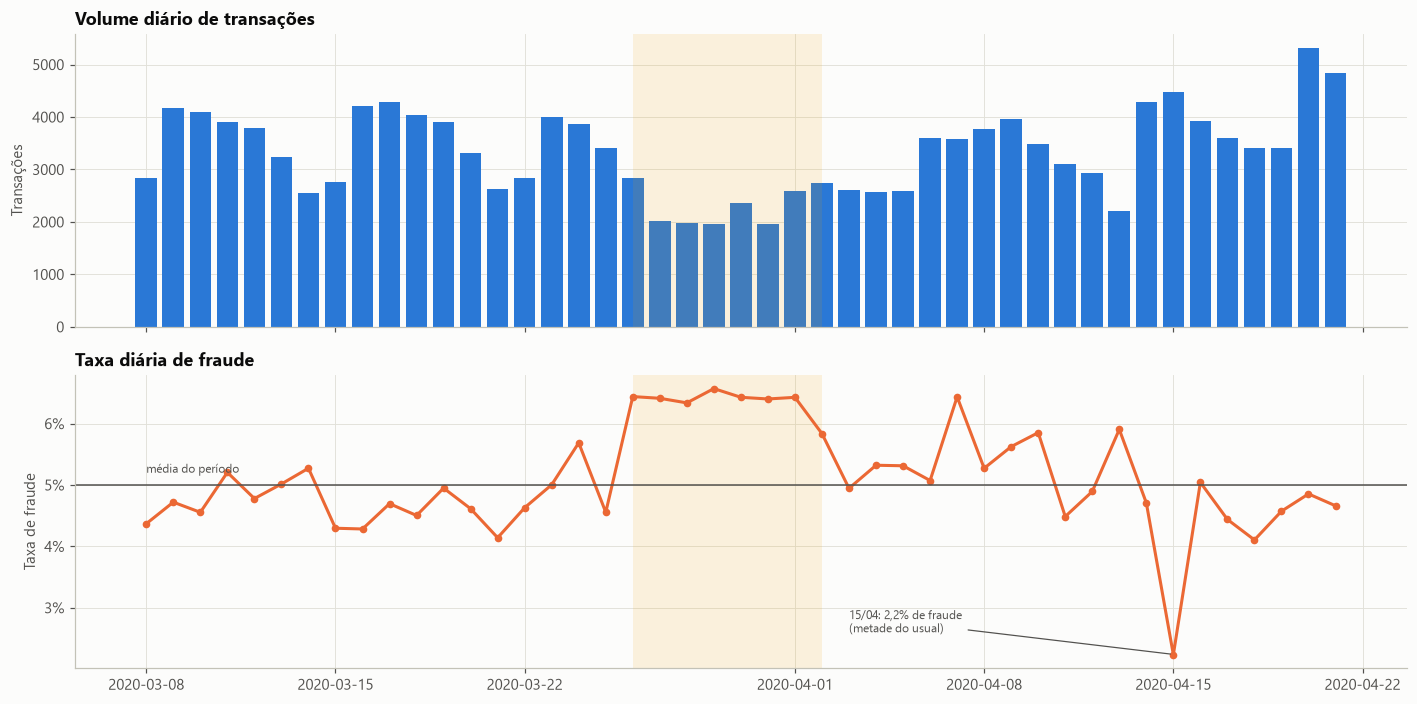

In [7]:
# Dois gráficos separados (um eixo cada): volume e taxa de fraude diária
fig, axes = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)
axes[0].bar(diario.index, diario["transacoes"], color=gr.AZUL, width=0.8)
axes[0].set(title="Volume diário de transações", ylabel="Transações")
axes[1].plot(diario.index, diario["taxa"], color=gr.LARANJA, marker="o", ms=4)
axes[1].axhline(df["fraude"].mean(), color=gr.TINTA_2, lw=1)
axes[1].text(diario.index[0], df["fraude"].mean() + 0.002, "média do período", color=gr.TINTA_2, fontsize=8)
axes[1].set(title="Taxa diária de fraude", ylabel="Taxa de fraude")
gr.formatar_pct(axes[1], casas=0)

# Destaques: período de menor volume / maior fraude e o dia atípico de 15/04
for ax in axes:
    ax.axvspan(pd.Timestamp("2020-03-26"), pd.Timestamp("2020-04-02"), color=gr.AMARELO, alpha=0.12, lw=0)
axes[1].annotate("15/04: 2,2% de fraude\n(metade do usual)", xy=(pd.Timestamp("2020-04-15"), 0.0224),
                 xytext=(pd.Timestamp("2020-04-03"), 0.026), fontsize=8, color=gr.TINTA_2,
                 arrowprops=dict(arrowstyle="-", color=gr.TINTA_2, lw=0.8))
plt.tight_layout()

**Achados temporais:**

1. **Mudança de regime entre 26/03 e 02/04 (faixa amarela):** o volume diário cai cerca de 35%
   (de ~3,5 mil para ~2,3 mil transações/dia) e a taxa de fraude sobe de ~4,7% para ~6,4%,
   voltando a ~4,9% depois. O período
   coincide com o início das quarentenas da COVID-19 na região (AR em 20/03, estados do BR a partir
   de 23/03). É uma **hipótese** plausível de choque de comportamento, tanto do consumidor quanto do
   fraudador.
2. **15/04 é um dia atípico:** volume normal, mas metade da taxa de fraude usual. Pode ser um evento
   de negócio (campanha) ou um problema de rotulagem/maturação. Vamos manter o dia na base, mas
   monitorar seu efeito na avaliação.
3. **Sazonalidade semanal:** fins de semana têm menos volume.

**Implicação:** o processo **não é estacionário**. Isso reforça a validação fora do tempo e exige
monitoramento de estabilidade em produção.

> **Maturação do rótulo:** em fraude, o rótulo vem de chargebacks/contestações que podem levar
> semanas para chegar. Num projeto real, confirmaríamos com o time de Analytics a data de corte dos
> rótulos. As últimas semanas podem estar sub-rotuladas, o que subestimaria a fraude no teste.

## 5. Estratégia de particionamento (out-of-time)

Dividimos a base **pela data**, simulando o uso real: treinar com o passado e decidir sobre o futuro.

| Partição | Período | Uso |
|---|---|---|
| **Treino** | 08/03 – 31/03 | ajuste dos modelos e das features |
| **Validação** | 01/04 – 10/04 | escolha de hiperparâmetros, calibração, ponto de corte |
| **Teste (OOT)** | 11/04 – 21/04 | **avaliação final, usada uma única vez** (notebook 07) |

Para comparar algoritmos com mais robustez, usamos também uma **validação cruzada temporal em janela
expansiva** dentro de treino + validação (3 folds semanais). Cada fold treina com tudo que vem antes da
janela de validação, sem nunca olhar o futuro.

In [8]:
df = df.sort_values("fecha").reset_index(drop=True)
df["particao"] = dados.atribuir_particao(df)

resumo_part = (df.groupby("particao", sort=False)
                 .agg(inicio=("fecha", "min"), fim=("fecha", "max"), transacoes=("fraude", "size"),
                      fraudes=("fraude", "sum"), taxa_fraude=("fraude", "mean"),
                      valor_total=("monto", "sum")))
resumo_part["%_base"] = resumo_part["transacoes"] / len(df)
resumo_part

,inicio,fim,transacoes,fraudes,taxa_fraude,valor_total,%_base
particao,,,,,,,
treino,2020-03-08 00:02:15,2020-03-31 23:56:36,76961,3877,0.0504,"3,522,441.7000",0.5131
validacao,2020-04-01 00:00:45,2020-04-10 23:59:43,31505,1769,0.0561,"1,283,646.3400",0.2100
teste,2020-04-11 00:00:44,2020-04-21 23:59:56,41534,1854,0.0446,"1,722,382.0800",0.2769


In [9]:
# Folds temporais (janela expansiva) dentro de treino+validação
dev = df[df["particao"] != "teste"].reset_index(drop=True)
linhas = []
for k, (idx_tr, idx_va) in enumerate(dados.folds_temporais(dev["fecha"]), start=1):
    linhas.append({
        "fold": k,
        "treino_ate": dev.loc[idx_tr, "fecha"].max().date(),
        "valida_de": dev.loc[idx_va, "fecha"].min().date(),
        "valida_ate": dev.loc[idx_va, "fecha"].max().date(),
        "n_treino": len(idx_tr), "n_valid": len(idx_va),
        "taxa_fraude_valid": dev.loc[idx_va, "fraude"].mean(),
    })
pd.DataFrame(linhas).set_index("fold")

,treino_ate,valida_de,valida_ate,n_treino,n_valid,taxa_fraude_valid
fold,,,,,,
1,2020-03-21,2020-03-22,2020-03-28,49731,20935,0.0546
2,2020-03-28,2020-03-29,2020-04-04,70666,16800,0.0595
3,2020-04-04,2020-04-05,2020-04-10,87466,21000,0.0560


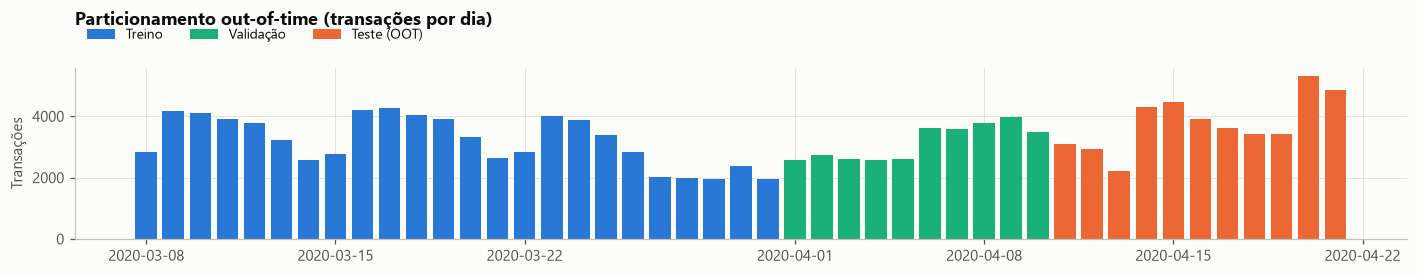

In [10]:
# Linha do tempo das partições
fig, ax = plt.subplots(figsize=(13, 2.6))
cores = {"treino": gr.AZUL, "validacao": gr.VERDE_AGUA, "teste": gr.LARANJA}
nomes = {"treino": "Treino", "validacao": "Validação", "teste": "Teste (OOT)"}
for part, g in df.groupby("particao", sort=False):
    d = g.set_index("fecha").resample("D").size()
    ax.bar(d.index, d.values, color=cores[part], width=0.8, label=nomes[part])
ax.set_ylabel("Transações")
ax.set_title("Particionamento out-of-time (transações por dia)", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.08), ncol=3)
plt.tight_layout()

## 6. Persistência da base particionada

In [11]:
cfg.DIR_PROCESSADO.mkdir(parents=True, exist_ok=True)
df.to_parquet(cfg.ARQUIVO_BASE, index=False)
print("Base salva em", cfg.ARQUIVO_BASE.relative_to(cfg.RAIZ), "->", df.shape)

Base salva em data\processed\base.parquet -> (150000, 21)


## 7. Conclusões desta etapa

- **150 mil transações, 5% de fraude, 45 dias.** É um problema desbalanceado, com custo assimétrico e
  decisão binária. As métricas serão PR AUC, ROC AUC/KS, Recall @ FPR e, no fim, **lucro em R$**.
- **Dados limpos estruturalmente** (sem duplicatas), mas com particularidades:
  - nulos em blocos (`b`+`c`, `d`+`m`) e **nulos informativos**, que não serão imputados cegamente;
  - `f` com valores negativos (provável código especial do sistema de origem);
  - `k` com um valor distinto por linha, candidata a ruído (será testada no notebook 03).
- **O processo não é estacionário:** há mudança de regime no fim de março e um dia anômalo em 15/04.
  Isso justifica a **validação out-of-time** e o monitoramento contínuo em produção.
- **Particionamento definido:** treino (08/03–31/03), validação (01/04–10/04) e teste OOT
  (11/04–21/04, intocado até o notebook 07).

➡️ **Próximo passo (02):** entender a fundo o score atual, o *baseline* a ser batido.